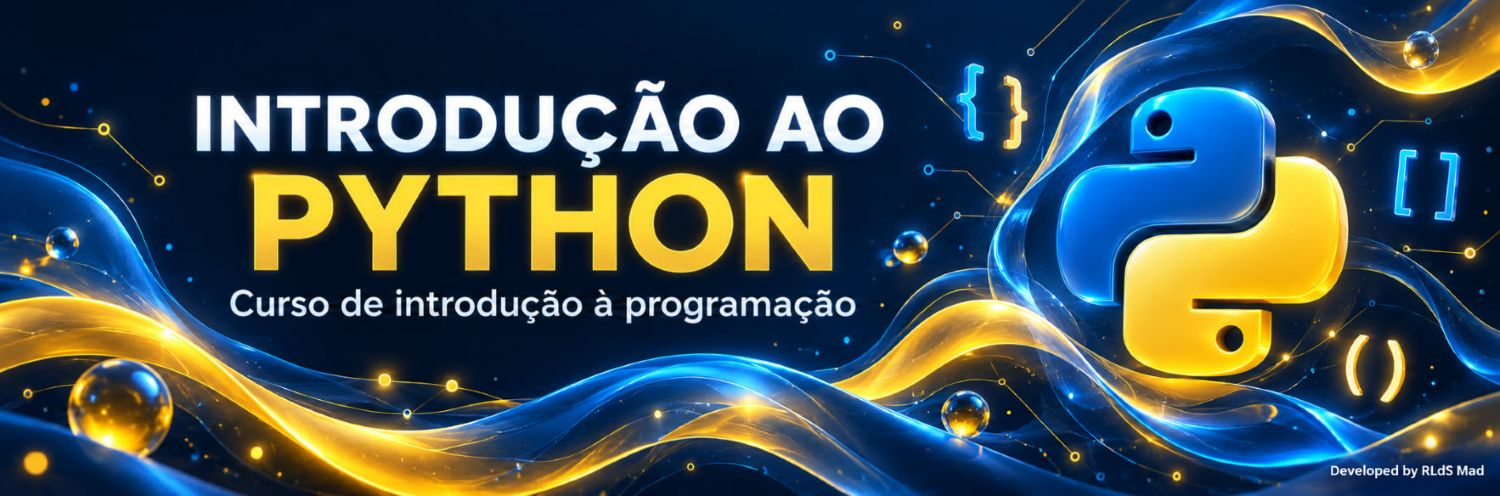

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_16_ScikitLearn_PyTorch.ipynb)

# Nível IA · Módulo 16 – scikit-learn e PyTorch juntos
## O que cada biblioteca faz melhor, e como pô-las a trabalhar em conjunto

O scikit-learn e o PyTorch aparecem muitas vezes como alternativas, mas fazem coisas diferentes. O scikit-learn dá modelos prontos (incluindo as árvores do N3_15, que o PyTorch não tem) e, sobretudo, a **infraestrutura à volta do modelo**: pré-processamento, `Pipeline`, validação cruzada, pesquisa de hiperparâmetros e métricas. O PyTorch dá **peças** (camadas, perdas, otimizadores, gradientes automáticos) para montar modelos que não existem prontos. O N3_05 já mostrou, no caso do abandono de clientes, que uma rede neuronal não ganha automaticamente a modelos clássicos em dados tabulares. Este módulo responde a outra pergunta: **quando é que o PyTorch acrescenta alguma coisa, e como se usa sem perder as ferramentas do scikit-learn?**

Usamos os mesmos clientes da operadora do N3_15 e, na secção 5, a função de Friedman do mesmo módulo.

> **Objetivos:** perceber que um modelo do scikit-learn é um modelo, uma perda e um otimizador já montados, reproduzindo a regressão logística em PyTorch até à oitava casa decimal; escrever um modelo PyTorch com a interface do scikit-learn e usá-lo em `Pipeline`, `cross_val_score` e `GridSearchCV`; tratar custos de erro diferentes por quatro caminhos e saber quando o PyTorch é necessário; representar uma variável categórica com centenas de valores por *one-hot*, codificação pelo alvo e *embeddings*; reconhecer em que tipo de problema uma rede ganha às árvores.

**Pré-requisitos:** N3_05 (PyTorch), N3_15 (árvores, florestas e *boosting*) e N2_05 (`Pipeline` e `GridSearchCV`).

| Secção | Tema |
| --- | --- |
| 0. Preparação | bibliotecas, dados e vocabulário |
| 1. A mesma regressão logística | scikit-learn e PyTorch, coeficiente a coeficiente |
| 2. Um modelo PyTorch com a interface do scikit-learn | `fit`, `predict`, `Pipeline` e `GridSearchCV` |
| 3. Erros com custos diferentes | limiar, pesos e uma perda própria |
| 4. Categorias com muitos valores | *one-hot*, codificação pelo alvo e *embeddings* |
| 5. Quando é que a rede ganha? | uma função suave e uma tabela com degraus |
| 6. Guia prático | que ferramenta para quê |
| 7. Experimenta | três exercícios com solução |

## 0. Preparação

### 0.1 Bibliotecas e dados

São precisos o PyTorch (instruções no N3_05, secção 0.1) e o scikit-learn 1.3 ou mais recente (por causa do `TargetEncoder`). Todo o módulo corre no CPU em menos de um minuto.

O gerador de clientes é o do N3_15: 2000 clientes, dos quais 25 % ficam para teste, e um conjunto de 10 000 clientes novos para medir com precisão. Lembra-te de que três em cada quatro clientes ficam e de que a idade é irrelevante.

In [1]:
# Executar esta célula

import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.datasets import make_friedman1
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

try:
    import torch
    from torch import nn
except ImportError:
    raise ImportError("O PyTorch não está instalado. Vê a secção 0.1 do N3_05.")

plt.rcParams.update({"figure.dpi": 100})
torch.manual_seed(0)
print(f"PyTorch {torch.__version__} | scikit-learn {sklearn.__version__}")


def gerar_clientes(n, semente=0):
    """Os clientes do N3_15: atributos e rótulo 1 = cancelou o contrato."""
    rng = np.random.default_rng(semente)
    meses = rng.integers(1, 73, n)
    mensalidade = np.round(rng.uniform(20, 120, n), 2)
    chamadas = rng.poisson(1.5, n)
    idade = rng.integers(18, 80, n)
    contrato = rng.choice(["mensal", "anual", "bienal"], n, p=[0.5, 0.3, 0.2])
    z = (-2.5 + 4.0 * (contrato == "mensal") - 2.0 * (contrato == "bienal") + 2.25 * (chamadas >= 3)
         + 3.0 * ((mensalidade > 85) & (meses < 12)) - 0.0625 * meses + 0.025 * (mensalidade - 70))
    cancelou = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
    dados = pd.DataFrame({"meses_cliente": meses, "mensalidade": mensalidade, "chamadas_suporte": chamadas,
                          "idade": idade, "contrato": contrato})
    return dados, cancelou


dados, y = gerar_clientes(2000)
X = pd.get_dummies(dados, columns=["contrato"], dtype=float)
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
dados_novos, y_novos = gerar_clientes(10000, semente=1)
X_novos = pd.get_dummies(dados_novos, columns=["contrato"], dtype=float)[X.columns]
print(f"Treino {len(X_treino)}, teste {len(X_teste)}, clientes novos {len(X_novos)} | colunas: {list(X.columns)}")

PyTorch 2.15.0+cu132 | scikit-learn 1.9.1
Treino 1500, teste 500, clientes novos 10000 | colunas: ['meses_cliente', 'mensalidade', 'chamadas_suporte', 'idade', 'contrato_anual', 'contrato_bienal', 'contrato_mensal']


### 0.2 Vocabulário

| Termo | Significado |
| --- | --- |
| **Estimador** | no scikit-learn, qualquer objeto com `fit`; os classificadores têm também `predict` e `predict_proba` |
| **Hiperparâmetro** | um argumento do construtor do estimador (`C`, `max_depth`...), fixado antes do treino |
| **Atributo aprendido** | o que o `fit` calcula; por convenção, o nome acaba em `_` (`coef_`, `classes_`) |
| **Perda** (*loss*) | a função que o treino minimiza; numa classificação binária, normalmente a entropia cruzada |
| **Regularização L2** | uma parcela da perda proporcional ao quadrado dos pesos, que os mantém pequenos |
| **Paragem antecipada** | parar o treino quando o erro num conjunto de validação deixa de melhorar |
| **Custo de um erro** | quanto custa, no problema real, um falso negativo ou um falso positivo |
| ***Embedding*** | um vetor aprendido para cada valor de uma variável categórica |
| **Codificação pelo alvo** | substituir cada categoria pela média do rótulo nessa categoria, calculada com validação cruzada |

## 1. A mesma regressão logística nas duas bibliotecas

A `LogisticRegression` do scikit-learn parece uma caixa fechada, mas é a soma de três peças. O **modelo** é linear, $z = w \cdot x + b$, com probabilidade $\sigma(z)$. A **perda** é a entropia cruzada somada sobre os exemplos mais uma penalização L2 dos pesos (não do termo independente), controlada pelo hiperparâmetro $C$:

$$\min_{w,\,b} \; C \sum_{i=1}^{n} \ell\big(y_i, \sigma(w \cdot x_i + b)\big) + \frac{1}{2}\lVert w \rVert^2$$

O **otimizador**, por omissão, é o L-BFGS, um método de segunda ordem aproximado. No PyTorch montamos as três peças à mão: dois tensores de parâmetros, a mesma perda escrita com `binary_cross_entropy_with_logits` e o otimizador `torch.optim.LBFGS`. Usamos precisão dupla (`float64`) e critérios de paragem apertados nos dois lados, para que a comparação meça diferenças reais e não arredondamentos.

In [2]:
# Executar esta célula

escala = StandardScaler().fit(X_treino)
A_treino, A_teste, A_novos = (escala.transform(M) for M in (X_treino, X_teste, X_novos))
C = 1.0

sk_log = LogisticRegression(C=C, max_iter=5000, tol=1e-10).fit(A_treino, y_treino)

At = torch.tensor(A_treino, dtype=torch.float64)
yt = torch.tensor(y_treino, dtype=torch.float64)
w = torch.zeros(At.shape[1], dtype=torch.float64, requires_grad=True)
b = torch.zeros(1, dtype=torch.float64, requires_grad=True)
otimizador = torch.optim.LBFGS([w, b], lr=1, max_iter=500, tolerance_grad=1e-12, tolerance_change=1e-14,
                               line_search_fn="strong_wolfe")


def perda_fechada():
    """O L-BFGS precisa de reavaliar a perda várias vezes por passo, por isso recebe uma função."""
    otimizador.zero_grad()
    perda = C * nn.functional.binary_cross_entropy_with_logits(At @ w + b, yt, reduction="sum") + 0.5 * (w ** 2).sum()
    perda.backward()
    return perda


otimizador.step(perda_fechada)
comparacao = pd.DataFrame({"scikit-learn": sk_log.coef_[0], "PyTorch": w.detach().numpy()}, index=X.columns)
print(comparacao.round(4))
print(f"\nMaior diferença nos pesos: {np.abs(w.detach().numpy() - sk_log.coef_[0]).max():.1e} | "
      f"no termo independente: {abs(b.item() - sk_log.intercept_[0]):.1e}")

                  scikit-learn  PyTorch
meses_cliente          -1.3882  -1.3882
mensalidade             0.7593   0.7593
chamadas_suporte        0.6508   0.6508
idade                  -0.0602  -0.0602
contrato_anual         -0.3215  -0.3215
contrato_bienal        -1.1179  -1.1179
contrato_mensal         1.1977   1.1977

Maior diferença nos pesos: 1.7e-08 | no termo independente: 9.1e-09


Os sete pesos coincidem em todas as casas decimais mostradas. A maior diferença é de 1,7 × 10⁻⁸ nos pesos e de 9,1 × 10⁻⁹ no termo independente, ou seja, ao nível da tolerância do otimizador. As duas bibliotecas resolvem o mesmo problema de otimização e chegam à mesma solução. O scikit-learn não faz magia: escolhe por nós um modelo, uma perda, uma regularização e um otimizador que funcionam bem em conjunto, e esconde-os atrás de `fit`.

Um pormenor da fórmula: a perda é **somada** sobre os exemplos, e a penalização não depende de $n$. Com mais dados, a parte dos dados pesa mais e a regularização conta menos, para o mesmo `C`. No PyTorch é habitual usar a perda **média** e o `weight_decay`; para obter o mesmo modelo é preciso converter um no outro, como fizemos aqui ao escrever a perda tal como o scikit-learn a define.

## 2. Um modelo PyTorch com a interface do scikit-learn

### 2.1 O contrato de um estimador

O que torna as ferramentas do scikit-learn tão úteis é que todas falam a mesma língua. Um `Pipeline`, o `cross_val_score` ou o `GridSearchCV` funcionam com **qualquer** objeto que respeite um pequeno contrato:

- o construtor `__init__` só **guarda** os hiperparâmetros, com os mesmos nomes dos argumentos, e não faz mais nada;
- `fit(X, y)` treina e devolve `self`; o que aprende fica em atributos terminados em `_`;
- um classificador tem `predict` e `predict_proba` e guarda as classes em `classes_`.

Herdando de `BaseEstimator`, ganhamos de graça `get_params` e `set_params`, que o `GridSearchCV` usa para mudar hiperparâmetros, e a compatibilidade com `clone`, que cria uma cópia **por treinar** para cada *fold*. `ClassifierMixin` e `RegressorMixin` acrescentam o método `score`.

Escrevemos uma rede com duas camadas escondidas, treinada com Adam em mini-lotes, e com **paragem antecipada**: separa internamente uma fração do treino para validação, guarda os pesos da melhor época e para quando a perda de validação não melhora durante `paciencia` épocas. A parte comum fica numa classe base; o classificador e o regressor só mudam a perda e a forma de prever.

In [3]:
# Executar esta célula

class _RedeBase(BaseEstimator):
    def __init__(self, escondida=64, camadas=2, lr=3e-3, weight_decay=1e-4, lote=64, epocas_max=300,
                 paciencia=20, fracao_validacao=0.2, semente=0):
        self.escondida = escondida
        self.camadas = camadas
        self.lr = lr
        self.weight_decay = weight_decay
        self.lote = lote
        self.epocas_max = epocas_max
        self.paciencia = paciencia
        self.fracao_validacao = fracao_validacao
        self.semente = semente

    def _construir(self, n_entradas):
        blocos, d = [], n_entradas
        for _ in range(self.camadas):
            blocos += [nn.Linear(d, self.escondida), nn.ReLU()]
            d = self.escondida
        return nn.Sequential(*blocos, nn.Linear(d, 1))

    def _ajustar(self, X, y, perda):
        torch.manual_seed(self.semente)
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)
        ordem = np.random.default_rng(self.semente).permutation(len(X))
        n_val = int(self.fracao_validacao * len(X))
        Xv, yv = torch.tensor(X[ordem[:n_val]]), torch.tensor(y[ordem[:n_val]])
        Xt, yt = torch.tensor(X[ordem[n_val:]]), torch.tensor(y[ordem[n_val:]])
        self.rede_ = self._construir(X.shape[1])
        otimizador = torch.optim.Adam(self.rede_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        melhor, sem_melhorar, self.historico_ = np.inf, 0, []
        for epoca in range(1, self.epocas_max + 1):
            self.rede_.train()
            permutacao = torch.randperm(len(Xt))
            for i in range(0, len(Xt), self.lote):
                lote = permutacao[i:i + self.lote]
                otimizador.zero_grad()
                perda(self.rede_(Xt[lote]).squeeze(1), yt[lote]).backward()
                otimizador.step()
            self.rede_.eval()
            with torch.no_grad():
                perda_val = perda(self.rede_(Xv).squeeze(1), yv).item()
            self.historico_.append(perda_val)
            if perda_val < melhor - 1e-4:
                melhor, sem_melhorar, self.melhor_epoca_ = perda_val, 0, epoca
                melhores_pesos = copy.deepcopy(self.rede_.state_dict())
            else:
                sem_melhorar += 1
                if sem_melhorar >= self.paciencia:
                    break
        self.rede_.load_state_dict(melhores_pesos)
        return self

    def _saida(self, X):
        self.rede_.eval()
        with torch.no_grad():
            return self.rede_(torch.tensor(np.asarray(X, dtype=np.float32))).squeeze(1).numpy()


class RedeClassificador(ClassifierMixin, _RedeBase):
    def fit(self, X, y):
        self.classes_ = np.unique(y)  # assume duas classes, codificadas 0 e 1
        return self._ajustar(X, y, nn.functional.binary_cross_entropy_with_logits)

    def predict_proba(self, X):
        p = 1 / (1 + np.exp(-self._saida(X)))
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return self.classes_[(self.predict_proba(X)[:, 1] > 0.5).astype(int)]


class RedeRegressor(RegressorMixin, _RedeBase):
    def fit(self, X, y):
        self.media_, self.desvio_ = float(np.mean(y)), float(np.std(y))  # treina com y padronizado
        return self._ajustar(X, (np.asarray(y) - self.media_) / self.desvio_, nn.functional.mse_loss)

    def predict(self, X):
        return self._saida(X) * self.desvio_ + self.media_


rede = RedeClassificador(escondida=32)
print(rede)
print("Hiperparâmetros:", rede.get_params())
copia = clone(rede.set_params(escondida=16))
print("Cópia por treinar:", copia, "| tem rede_?", hasattr(copia, "rede_"))

RedeClassificador(escondida=32)
Hiperparâmetros: {'camadas': 2, 'epocas_max': 300, 'escondida': 32, 'fracao_validacao': 0.2, 'lote': 64, 'lr': 0.003, 'paciencia': 20, 'semente': 0, 'weight_decay': 0.0001}
Cópia por treinar: RedeClassificador(escondida=16) | tem rede_? False


### 2.2 Dentro das ferramentas do scikit-learn

Agora a rede entra num `Pipeline` com a padronização, que a rede precisa e as árvores não. Dentro do `Pipeline`, o `StandardScaler` é ajustado só com a parte de treino de cada *fold*, sem fuga de informação. Comparamos, com a mesma validação cruzada, com a regressão logística e o `HistGradientBoostingClassifier`, e fazemos uma pequena pesquisa de hiperparâmetros com o `GridSearchCV`. Os nomes dos hiperparâmetros dentro de um `Pipeline` são `<passo>__<hiperparâmetro>`, como no N2_05.

                      mean    std
regressão logística  0.865  0.021
boosting (HGB)       0.861  0.022
rede (PyTorch)       0.873  0.032
2 s


                                                                         params  mean_test_score  std_test_score
 {'redeclassificador__escondida': 8, 'redeclassificador__weight_decay': 0.0001}            0.864           0.022
   {'redeclassificador__escondida': 8, 'redeclassificador__weight_decay': 0.01}            0.867           0.022
{'redeclassificador__escondida': 64, 'redeclassificador__weight_decay': 0.0001}            0.873           0.028
  {'redeclassificador__escondida': 64, 'redeclassificador__weight_decay': 0.01}            0.868           0.025
Melhor: {'redeclassificador__escondida': 64, 'redeclassificador__weight_decay': 0.0001} | teste 0.820 | paragem na época 2 | 7 s


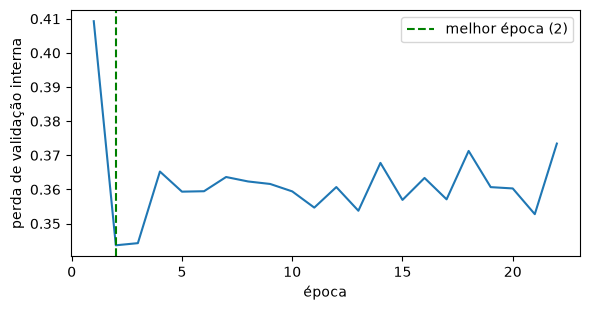

In [4]:
# Executar esta célula

cv = StratifiedKFold(5, shuffle=True, random_state=0)
inicio = time.time()
candidatos = {
    "regressão logística": make_pipeline(StandardScaler(), LogisticRegression()),
    "boosting (HGB)": HistGradientBoostingClassifier(early_stopping=True, random_state=0),
    "rede (PyTorch)": make_pipeline(StandardScaler(), RedeClassificador()),
}
validacao = pd.DataFrame({nome: cross_val_score(m, X_treino, y_treino, cv=cv) for nome, m in candidatos.items()})
print(validacao.agg(["mean", "std"]).T.round(3))
print(f"{time.time() - inicio:.0f} s")

inicio = time.time()
pesquisa = GridSearchCV(make_pipeline(StandardScaler(), RedeClassificador()),
                        {"redeclassificador__escondida": [8, 64], "redeclassificador__weight_decay": [1e-4, 1e-2]},
                        cv=cv).fit(X_treino, y_treino)
res = pd.DataFrame(pesquisa.cv_results_)
print(res[["params", "mean_test_score", "std_test_score"]].round(3).to_string(index=False))
melhor_rede = pesquisa.best_estimator_[-1]
print(f"Melhor: {pesquisa.best_params_} | teste {pesquisa.score(X_teste, y_teste):.3f} | "
      f"paragem na época {melhor_rede.melhor_epoca_} | {time.time() - inicio:.0f} s")

plt.figure(figsize=(6, 3.2))
plt.plot(np.arange(1, len(melhor_rede.historico_) + 1), melhor_rede.historico_)
plt.axvline(melhor_rede.melhor_epoca_, color="green", ls="--", label=f"melhor época ({melhor_rede.melhor_epoca_})")
plt.xlabel("época")
plt.ylabel("perda de validação interna")
plt.legend()
plt.tight_layout()
plt.show()

A rede funcionou dentro do `Pipeline`, do `cross_val_score` e do `GridSearchCV` sem nenhuma adaptação, porque respeita o contrato. Em validação cruzada, os três modelos ficam entre 0,861 e 0,873, com desvios-padrão entre 0,021 e 0,032: estão empatados. A rede é a que mais varia de *fold* para *fold*. Na pesquisa de hiperparâmetros, as quatro combinações ficam entre 0,864 e 0,873, de novo dentro do ruído.

A melhor combinação, ajustada de novo em todo o treino, acerta em 0,820 dos clientes de teste, um pouco abaixo dos 0,836 a 0,854 que os modelos da comparação final do N3_15 tiveram neste mesmo teste. O gráfico mostra porquê: a perda na validação interna (300 clientes, 20 % do treino) atinge o mínimo na época 2, sobe logo a seguir e depois oscila, e a paragem antecipada fica com os pesos da época 2. Com uma validação tão pequena, a escolha da época é ruidosa, e uma rede com 64 neurónios por camada ajusta estes dados em muito poucas épocas. Lembra-te também de que, com 500 clientes de teste, o erro-padrão de uma exatidão perto de 0,85 é cerca de 0,016 (N3_15, secção 7.4).

A classe que escrevemos tem algumas dezenas de linhas. A biblioteca **skorch** faz o mesmo de forma geral, com muitas opções prontas (paragem antecipada, guardar o melhor modelo, GPU), e é a escolha natural num projeto real.

## 3. Erros com custos diferentes

No N3_15 (secção 7.5), um cliente que cancela sem ser assinalado custa mais do que uma proposta desnecessária. Suponhamos que um **falso negativo custa 5** e um **falso positivo custa 1**. Há quatro maneiras de levar isto em conta:

1. **Mudar o limiar**, sem mexer no modelo. Se $p$ é a probabilidade de cancelar, assinalar custa $(1-p) \cdot 1$ em média e não assinalar custa $p \cdot 5$; compensa assinalar quando $5p > 1 - p$, ou seja, $p > 1/6$.
2. **Pesar os exemplos no scikit-learn**, com `class_weight={0: 1, 1: 5}`: cada cliente que cancelou conta 5 vezes na perda.
3. **Pesar no PyTorch**, com `pos_weight=5` na `binary_cross_entropy_with_logits`, que é a mesma ideia.
4. **Escrever uma perda própria no PyTorch**, que é o **custo esperado** da decisão. Com $s = \sigma(z)$ a «vontade» suave de assinalar, o custo de um exemplo é $5\,y\,(1-s) + (1-y)\,s$, e minimiza-se a média diretamente.

Os caminhos 3 e 4 usam um modelo linear treinado com Adam. Medimos o custo total nos 10 000 clientes novos.

In [5]:
# Executar esta célula

def custo(previsto, verdadeiro=y_novos, c_fn=5, c_fp=1):
    vn, fp, fn, vp = confusion_matrix(verdadeiro, previsto).ravel()
    return {"custo total": c_fn * fn + c_fp * fp, "falsos negativos": fn, "falsos positivos": fp}


An = torch.tensor(A_treino, dtype=torch.float32)
yn = torch.tensor(y_treino, dtype=torch.float32)
Anovos = torch.tensor(A_novos, dtype=torch.float32)


def treinar_linear(perda, passos=3000):
    torch.manual_seed(0)
    modelo = nn.Linear(An.shape[1], 1)
    opt = torch.optim.Adam(modelo.parameters(), lr=0.05)
    for _ in range(passos):
        opt.zero_grad()
        perda(modelo(An).squeeze(1), yn).backward()
        opt.step()
    with torch.no_grad():
        return modelo(Anovos).squeeze(1).numpy()


def custo_esperado(z, y):
    s = torch.sigmoid(z)
    return (5 * y * (1 - s) + (1 - y) * s).mean()


p_log = LogisticRegression().fit(A_treino, y_treino).predict_proba(A_novos)[:, 1]
caminhos = {
    "sem custos (limiar 0,5)": custo(p_log > 0.5),
    "1. limiar 1/6": custo(p_log > 1 / 6),
    "2. scikit-learn, class_weight": custo(LogisticRegression(class_weight={0: 1, 1: 5}).fit(A_treino, y_treino).predict(A_novos)),
    "3. PyTorch, pos_weight": custo(treinar_linear(lambda z, y: nn.functional.binary_cross_entropy_with_logits(
        z, y, pos_weight=torch.tensor(5.0))) > 0),
    "4. PyTorch, custo esperado": custo(treinar_linear(custo_esperado) > 0),
}
print(pd.DataFrame(caminhos).T.to_string())

                               custo total  falsos negativos  falsos positivos
sem custos (limiar 0,5)               5389               978               499
1. limiar 1/6                         2951               225              1826
2. scikit-learn, class_weight         2947               232              1787
3. PyTorch, pos_weight                2950               233              1785
4. PyTorch, custo esperado            2964               191              2009


Sem ter os custos em conta, o modelo deixa escapar 978 cancelamentos e o custo total é 5389. Os quatro caminhos baixam-no para perto de metade e ficam todos entre 2947 e 2964. Os três primeiros são praticamente a mesma decisão (225 a 233 falsos negativos). A perda própria troca alguns falsos negativos por falsos positivos (191 e 2009), com um custo total quase igual.

A conclusão é deliberadamente modesta: **para custos fixos por tipo de erro, o PyTorch não é necessário**. O caminho mais simples é mudar o limiar, que nem obriga a treinar de novo quando os custos mudam (exercício 3). Uma perda própria só faz falta quando o objetivo não se escreve como uma perda padrão com pesos (pergunta 8 da verificação).

## 4. Categorias com muitos valores

### 4.1 Uma variável com 300 categorias

Suponhamos que a operadora conhece a **zona de residência** de cada cliente, uma de 300, e que cada zona tem o seu próprio efeito no cancelamento (há zonas com mais concorrência, por exemplo). Geramos uma versão dos clientes com essa variável: o efeito de cada zona é sorteado uma vez, igual em todos os conjuntos, e soma-se ao resto do cálculo. Com 2000 clientes há, em média, menos de 7 por zona; por isso usamos também um treino maior, de 8000.

Comparamos cinco maneiras de usar a zona, todas com um modelo linear por cima, para que a diferença venha só da representação:

- **ignorá-la**;
- ***one-hot***: uma coluna 0/1 por zona, 300 colunas, cada uma com o seu peso;
- **codificação pelo alvo** (`TargetEncoder`): cada zona é substituída pela taxa de cancelamento nessa zona, com encolhimento para a média global quando há poucos clientes e calculada com validação cruzada interna, para não usar o rótulo do próprio exemplo;
- ***embedding*** **de dimensão 1 e de dimensão 4** no PyTorch (`nn.Embedding`): cada zona recebe um vetor aprendido junto com o resto do modelo.

O `HistGradientBoostingClassifier` aceita categorias diretamente, mas só até 255 valores diferentes; a célula mostra o que acontece com 300.

In [6]:
# Executar esta célula

N_ZONAS = 300
EFEITO_ZONA = np.random.default_rng(123).normal(0, 1.2, N_ZONAS)  # o «mapa» verdadeiro, fixo
NUMERICAS = ["meses_cliente", "mensalidade", "chamadas_suporte", "idade"]


def gerar_clientes_zona(n, semente=0):
    rng = np.random.default_rng(semente)
    meses = rng.integers(1, 73, n)
    mensalidade = np.round(rng.uniform(20, 120, n), 2)
    chamadas = rng.poisson(1.5, n)
    idade = rng.integers(18, 80, n)
    contrato = rng.choice(["mensal", "anual", "bienal"], n, p=[0.5, 0.3, 0.2])
    zona = rng.integers(0, N_ZONAS, n)
    z = (-2.5 + 4.0 * (contrato == "mensal") - 2.0 * (contrato == "bienal") + 2.25 * (chamadas >= 3)
         + 3.0 * ((mensalidade > 85) & (meses < 12)) - 0.0625 * meses + 0.025 * (mensalidade - 70) + EFEITO_ZONA[zona])
    cancelou = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
    return pd.DataFrame({"meses_cliente": meses, "mensalidade": mensalidade, "chamadas_suporte": chamadas,
                         "idade": idade, "contrato": contrato, "zona": zona}), cancelou


class ModeloEmbedding(nn.Module):
    """Modelo linear sobre os atributos numéricos e um embedding da zona."""

    def __init__(self, n_atributos, dimensao):
        super().__init__()
        self.zona = nn.Embedding(N_ZONAS, dimensao)
        self.linear = nn.Linear(n_atributos + dimensao, 1)

    def forward(self, x, zona):
        return self.linear(torch.cat([x, self.zona(zona)], dim=1)).squeeze(1)


def treinar_embedding(Xn, zonas, y, dimensao, epocas=60):
    torch.manual_seed(0)
    modelo = ModeloEmbedding(Xn.shape[1], dimensao)
    opt = torch.optim.Adam(modelo.parameters(), lr=0.02, weight_decay=1e-3)
    Xn, zonas, y = torch.tensor(Xn, dtype=torch.float32), torch.tensor(zonas), torch.tensor(y, dtype=torch.float32)
    for _ in range(epocas):
        ordem = torch.randperm(len(Xn))
        for i in range(0, len(Xn), 128):
            lote = ordem[i:i + 128]
            opt.zero_grad()
            nn.functional.binary_cross_entropy_with_logits(modelo(Xn[lote], zonas[lote]), y[lote]).backward()
            opt.step()
    return modelo


dados_z_novos, y_z_novos = gerar_clientes_zona(10000, semente=1)
base = [("num", StandardScaler(), NUMERICAS), ("contrato", OneHotEncoder(), ["contrato"])]
inicio = time.time()
resultados_zona, modelos_emb = {}, {}
for n in (2000, 8000):
    dz, yz = gerar_clientes_zona(n, semente=0)
    prob = {}
    prob["ignorar a zona"] = make_pipeline(ColumnTransformer(base), LogisticRegression(max_iter=2000)).fit(dz, yz)
    prob["one-hot"] = make_pipeline(ColumnTransformer(base + [("zona", OneHotEncoder(handle_unknown="ignore"), ["zona"])]),
                                    LogisticRegression(max_iter=2000)).fit(dz, yz)
    prob["codificação pelo alvo"] = make_pipeline(ColumnTransformer(base + [("zona", TargetEncoder(random_state=0), ["zona"])]),
                                                  LogisticRegression(max_iter=2000)).fit(dz, yz)
    prob = {k: m.predict_proba(dados_z_novos)[:, 1] for k, m in prob.items()}
    prep = ColumnTransformer(base).fit(dz)
    for d in (1, 4):
        m = treinar_embedding(prep.transform(dz), dz["zona"].to_numpy(), yz, d)
        modelos_emb[(n, d)] = m
        with torch.no_grad():
            z = m(torch.tensor(prep.transform(dados_z_novos), dtype=torch.float32), torch.tensor(dados_z_novos["zona"].to_numpy()))
        prob[f"embedding, dimensão {d}"] = torch.sigmoid(z).numpy()
    resultados_zona[f"treino {n}: AUC"] = {k: roc_auc_score(y_z_novos, p) for k, p in prob.items()}
    resultados_zona[f"treino {n}: exatidão"] = {k: np.mean((p > 0.5) == y_z_novos) for k, p in prob.items()}
print(pd.DataFrame(resultados_zona).round(3))
print(f"{time.time() - inicio:.0f} s")

try:
    dz_cat = dz.astype({"contrato": "category", "zona": "category"})
    HistGradientBoostingClassifier(categorical_features="from_dtype").fit(dz_cat, yz)
    print("O HistGradientBoostingClassifier aceitou as 300 zonas como categoria.")
except ValueError as erro:
    print(f"HistGradientBoostingClassifier com a zona como categoria: {erro}")

                       treino 2000: AUC  treino 2000: exatidão  \
ignorar a zona                    0.891                  0.828   
one-hot                           0.903                  0.842   
codificação pelo alvo             0.898                  0.837   
embedding, dimensão 1             0.888                  0.832   
embedding, dimensão 4             0.889                  0.834   

                       treino 8000: AUC  treino 8000: exatidão  
ignorar a zona                    0.892                  0.828  
one-hot                           0.913                  0.850  
codificação pelo alvo             0.907                  0.846  
embedding, dimensão 1             0.912                  0.851  
embedding, dimensão 4             0.912                  0.851  
4 s
HistGradientBoostingClassifier com a zona como categoria: Categorical feature 'zona' is expected to have a cardinality <= 255 but actually has a cardinality of 300.


Com 2000 clientes de treino, menos de 7 por zona em média, a zona ajuda pouco: a AUC passa de 0,891 (sem a zona) para 0,903 com *one-hot*, e os *embeddings* ficam ao nível de ignorá-la (0,888 e 0,889). Com tão poucos exemplos por zona, cada efeito é estimado com muito ruído. Com 8000 clientes, todos os métodos que usam a zona ganham: *one-hot* 0,913, *embeddings* 0,912, codificação pelo alvo 0,907, contra 0,892 sem a zona.

O *embedding* de dimensão 1 e o *one-hot* dão praticamente o mesmo resultado, como seria de esperar (pergunta 9), e a dimensão 4 não acrescenta nada: o efeito verdadeiro de cada zona é um só número e o modelo por cima é linear. A codificação pelo alvo fica ligeiramente atrás, mas é a mais compacta, com uma coluna em vez de 300, e é a que serve a modelos que não lidam bem com centenas de colunas. Por fim, o `HistGradientBoostingClassifier` recusa a zona como categoria, porque tem mais de 255 valores; as saídas seriam a codificação pelo alvo ou agrupar as zonas com poucos clientes.

### 4.2 O que o *embedding* aprendeu

Com dimensão 1, o *embedding* dá um número a cada zona. Como os dados são gerados, podemos compará-lo com o efeito verdadeiro de cada zona.

Correlação entre o efeito aprendido e o verdadeiro, nas 300 zonas: 0.830
Clientes por zona no treino de 8000: de 11 a 49, mediana 26


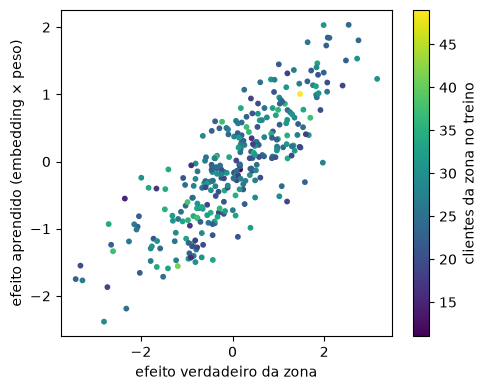

In [7]:
# Executar esta célula

aprendido = modelos_emb[(8000, 1)].zona.weight.detach().numpy()[:, 0]
peso = modelos_emb[(8000, 1)].linear.weight.detach().numpy()[0, -1]  # o embedding entra no modelo multiplicado por este peso
efeito_aprendido = aprendido * peso
contagem = np.bincount(gerar_clientes_zona(8000, semente=0)[0]["zona"], minlength=N_ZONAS)
r = np.corrcoef(efeito_aprendido, EFEITO_ZONA)[0, 1]
print(f"Correlação entre o efeito aprendido e o verdadeiro, nas 300 zonas: {r:.3f}")
print(f"Clientes por zona no treino de 8000: de {contagem.min()} a {contagem.max()}, mediana {np.median(contagem):.0f}")

plt.figure(figsize=(5, 4))
plt.scatter(EFEITO_ZONA, efeito_aprendido, s=10, c=contagem, cmap="viridis")
plt.colorbar(label="clientes da zona no treino")
plt.xlabel("efeito verdadeiro da zona")
plt.ylabel("efeito aprendido (embedding × peso)")
plt.tight_layout()
plt.show()

A correlação entre o efeito aprendido e o verdadeiro é de 0,830, com 11 a 49 clientes por zona no treino (mediana 26). O *embedding* recuperou boa parte do «mapa» escondido sem que ninguém lhe dissesse o que é uma zona: deu a cada categoria uma posição aprendida a partir dos rótulos. Os pontos ficam numa reta com inclinação menor do que 1, porque a regularização (`weight_decay`) puxa os efeitos para zero, sobretudo nas zonas com menos clientes. É a mesma ideia dos *embeddings* de palavras do N3_07 e do N3_14, aqui com uma só dimensão.

## 5. Quando é que a rede ganha?

Uma rede com ativações ReLU representa funções **contínuas e suaves por troços**, com fronteiras de decisão oblíquas. Uma árvore representa funções **em degraus**, com fronteiras paralelas aos eixos (N3_15). A expectativa é que cada uma ganhe no terreno que lhe é natural. Testamos as duas nos dois tipos de problema, com a mesma rede da secção 2 (com paragem antecipada) e o `HistGradientBoosting`:

- **a função de Friedman** (N3_15, secção 7.1): suave, com uma interação em seno e um termo quadrático, 10 variáveis das quais 5 contam. 2000 exemplos de treino com ruído; o erro é medido face à função verdadeira em 5000 pontos novos;
- **os clientes da operadora**: regras em degrau (contrato mensal, três ou mais chamadas, clientes recentes com mensalidade alta), e uma segunda versão com **20 colunas de ruído** a mais, porque as variáveis irrelevantes são um dos pontos fracos conhecidos das redes em dados tabulares (Grinsztajn et al., 2022).

In [8]:
# Executar esta célula

inicio = time.time()
X_f, y_f = make_friedman1(2000, noise=1.0, random_state=0)
X_f_novos, f_verdadeira = make_friedman1(5000, noise=0, random_state=1)
regressores = {"regressão linear": LinearRegression(),
               "boosting (HGB)": HistGradientBoostingRegressor(random_state=0),
               "rede (PyTorch)": make_pipeline(StandardScaler(), RedeRegressor())}
friedman = {}
for nome, m in regressores.items():
    t = time.time()
    m.fit(X_f, y_f)
    friedman[nome] = {"erro quadrático face a f": np.mean((m.predict(X_f_novos) - f_verdadeira) ** 2),
                      "tempo de treino (s)": time.time() - t}
print("Função de Friedman (2000 exemplos de treino):")
print(pd.DataFrame(friedman).T.round(3))

rng = np.random.default_rng(7)
clientes = {}
for extra in (0, 20):
    A, B = X_treino.copy(), X_novos.copy()
    for k in range(extra):
        A[f"ruido_{k}"] = rng.normal(size=len(A))
        B[f"ruido_{k}"] = rng.normal(size=len(B))
    for nome, m in {"regressão logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                    "boosting (HGB)": HistGradientBoostingClassifier(early_stopping=True, random_state=0),
                    "rede (PyTorch)": make_pipeline(StandardScaler(), RedeClassificador())}.items():
        p = m.fit(A, y_treino).predict_proba(B)[:, 1]
        clientes[(f"+{extra} colunas de ruído", nome)] = {"exatidão": np.mean((p > 0.5) == y_novos),
                                                          "AUC": roc_auc_score(y_novos, p)}
print("\nClientes (1500 de treino, avaliação nos 10 000 novos):")
print(pd.DataFrame(clientes).T.round(3))
print(f"{time.time() - inicio:.0f} s")

Função de Friedman (2000 exemplos de treino):
                  erro quadrático face a f  tempo de treino (s)
regressão linear                     5.970                0.002
boosting (HGB)                       0.784                0.211
rede (PyTorch)                       0.551                1.043



Clientes (1500 de treino, avaliação nos 10 000 novos):
                                          exatidão    AUC
+0 colunas de ruído  regressão logística     0.852  0.916
                     boosting (HGB)          0.860  0.910
                     rede (PyTorch)          0.848  0.912
+20 colunas de ruído regressão logística     0.852  0.913
                     boosting (HGB)          0.853  0.907
                     rede (PyTorch)          0.843  0.904
2 s


Na **função de Friedman**, a rede tem um erro de 0,551, contra 0,784 do *boosting*: cerca de 30 % menos. A regressão linear, com 5,970, mostra quanto da função é não linear. É o terreno natural da rede: uma função suave, com uma interação em seno, que as árvores só conseguem aproximar com muitos degraus. A rede demorou 0,9 s a treinar, contra 0,2 s do *boosting*.

Nos **clientes**, ninguém ganha: a exatidão fica entre 0,848 e 0,860 e a AUC entre 0,910 e 0,916, e a regressão logística continua com a melhor AUC. Com 20 colunas de ruído, os três perdem um pouco, e a rede é a que perde mais (AUC de 0,912 para 0,904), contra 0,910 para 0,907 no *boosting* e 0,916 para 0,913 na regressão logística.

A expectativa de que as árvores ganhassem nos clientes não se confirmou. As regras em degrau do gerador são poucas e entram numa probabilidade logística suave, terreno onde os três modelos funcionam bem. A vantagem clara de uma rede só apareceu na função suave; nos dados tabulares típicos, os resultados de Grinsztajn et al. (2022) e os deste módulo apontam no mesmo sentido: começar pelos modelos clássicos.

## 6. Guia prático

- **Começa pelo scikit-learn.** Uma regressão logística (ou linear) e um `HistGradientBoosting` são as referências em dados tabulares: treinam em segundos, precisam de pouca afinação e, como se viu aqui e no N3_05, muitas vezes não são batidos.
- **Usa a infraestrutura do scikit-learn para tudo,** incluindo modelos PyTorch: `Pipeline`, `ColumnTransformer`, validação cruzada, `GridSearchCV` e métricas. Basta embrulhar a rede com a interface de estimador (secção 2) ou usar o skorch.
- **Usa o PyTorch quando o problema o pede:** dados que não são uma tabela (imagens no N3_06, texto no N3_07 e N3_14, sequências no N3_12, grafos no N3_13); funções suaves com interações contínuas (secção 5); várias saídas ao mesmo tempo ou uma perda que não é uma perda padrão com pesos; muitos dados, com treino em mini-lotes e GPU.
- **Custos de erro diferentes:** muda o limiar de decisão (secção 3 e N3_15, secção 7.6). Pesos ou uma perda própria dão o mesmo para custos fixos.
- **Categorias com muitos valores:** a codificação pelo alvo é a mais simples e compacta; o *one-hot* com regularização funciona bem num modelo linear com dados suficientes; os *embeddings* fazem sentido quando já há uma rede, ou quando há várias variáveis categóricas grandes cuja estrutura vale a pena aprender.

## 7. Experimenta

**Exercício 1 – Outro valor de `C`.** Repete a comparação da secção 1 com `C = 0.01` (regularização forte). Os pesos continuam a coincidir? Compara os pesos com os de `C = 1`: o que fez a regularização?

In [9]:
# Escreve aqui o código do exercício 1

<details><summary><b>Ver uma solução possível</b></summary>

```python
C = 0.01
sk_forte = LogisticRegression(C=C, max_iter=5000, tol=1e-10).fit(A_treino, y_treino)
w = torch.zeros(At.shape[1], dtype=torch.float64, requires_grad=True)
b = torch.zeros(1, dtype=torch.float64, requires_grad=True)
otimizador = torch.optim.LBFGS([w, b], lr=1, max_iter=500, tolerance_grad=1e-12, tolerance_change=1e-14,
                               line_search_fn="strong_wolfe")
otimizador.step(perda_fechada)  # a função usa as variáveis globais C, w, b e otimizador
print(f"Maior diferença: {np.abs(w.detach().numpy() - sk_forte.coef_[0]).max():.1e}")
print(pd.DataFrame({"C=1": sk_log.coef_[0], "C=0.01": sk_forte.coef_[0]}, index=X.columns).round(3))
```

Os pesos voltam a coincidir, porque as duas bibliotecas minimizam exatamente a mesma função. Com `C = 0.01`, a penalização pesa cem vezes mais face aos dados, e todos os pesos encolhem em direção a zero; os das variáveis fracas (como a idade) ficam praticamente nulos.

</details>

**Exercício 2 – A rede num `Pipeline` com `ColumnTransformer`.** Em vez de usar as colunas já convertidas com `pd.get_dummies`, monta um `Pipeline` que recebe os dados originais (`dados`, com a coluna de texto `contrato`): um `ColumnTransformer` que padroniza as variáveis numéricas e aplica `OneHotEncoder` ao contrato, seguido de `RedeClassificador()`. Avalia-o com `cross_val_score` nos clientes de treino (usa os mesmos índices de `X_treino`).

In [10]:
# Escreve aqui o código do exercício 2

<details><summary><b>Ver uma solução possível</b></summary>

```python
dados_treino = dados.loc[X_treino.index]
modelo_completo = make_pipeline(
    ColumnTransformer([("num", StandardScaler(), ["meses_cliente", "mensalidade", "chamadas_suporte", "idade"]),
                       ("cat", OneHotEncoder(), ["contrato"])]),
    RedeClassificador())
notas = cross_val_score(modelo_completo, dados_treino, y_treino, cv=cv)
print(f"Validação cruzada: {notas.mean():.3f} ± {notas.std():.3f}")
```

O resultado deve ficar ao nível da rede da secção 2.2. A vantagem é prática: o `Pipeline` recebe os dados como estão, e todo o pré-processamento é ajustado só com a parte de treino de cada *fold*. Funciona porque o `RedeClassificador` respeita o contrato de estimador; o `ColumnTransformer` nem sabe que por trás está uma rede PyTorch.

</details>

**Exercício 3 – Outros custos.** Na secção 3, com um falso negativo a custar $c$ e um falso positivo a custar 1, o limiar ótimo é $1/(1+c)$. Para $c = 2$, $5$ e $20$, calcula o custo total nos clientes novos com (a) o limiar $1/(1+c)$ e (b) `LogisticRegression(class_weight={0: 1, 1: c})` com limiar 0,5. Os dois caminhos continuam equivalentes?

In [11]:
# Escreve aqui o código do exercício 3

<details><summary><b>Ver uma solução possível</b></summary>

```python
for c in (2, 5, 20):
    a = custo(p_log > 1 / (1 + c), c_fn=c)["custo total"]
    pesada = LogisticRegression(class_weight={0: 1, 1: c}).fit(A_treino, y_treino)
    b_ = custo(pesada.predict(A_novos), c_fn=c)["custo total"]
    print(f"c = {c:2d}: limiar 1/(1+c) -> {a} | class_weight -> {b_}")
```

Os dois caminhos dão custos próximos para todos os valores de $c$; na execução de referência, a maior diferença, com $c = 20$, foi de cerca de 2 %. Pesar a classe positiva por $c$ desloca a fronteira do modelo aproximadamente tanto como mudar o limiar para $1/(1+c)$; com um modelo bem especificado, como aqui, são praticamente a mesma decisão. Mudar o limiar tem a vantagem de não obrigar a treinar de novo quando os custos mudam.

</details>

## Verifica o que aprendeste

1. Que três peças compõem a `LogisticRegression` do scikit-learn, e qual é o papel de `C`?
2. Porque é que, na secção 1, se usou precisão dupla e critérios de paragem apertados?
3. O que é que o construtor de um estimador do scikit-learn deve e não deve fazer? Porquê?
4. Para que servem `get_params`, `set_params` e `clone` numa validação cruzada ou num `GridSearchCV`?
5. Porque é que o `StandardScaler` deve estar dentro do `Pipeline` e não ser aplicado antes da validação cruzada?
6. Como funciona a paragem antecipada da classe `RedeClassificador`, e porque é que guarda os pesos da melhor época?
7. Com um falso negativo a custar 5 e um falso positivo a custar 1, porque é que o limiar ótimo é 1/6?
8. Na secção 3, os quatro caminhos para os custos deram resultados parecidos. Em que situação é que uma perda própria no PyTorch seria realmente necessária?
9. Porque é que um *embedding* de dimensão 1 sobre um modelo linear é quase o mesmo que um *one-hot*?
10. Que problema tem o *one-hot* com uma variável de muitas categorias e poucos exemplos por categoria, e como o resolve a codificação pelo alvo?
11. Em que tipo de função se espera que uma rede ganhe a uma árvore, e porquê? E o contrário?
12. Dá três razões práticas para preferir o `HistGradientBoosting` a uma rede num problema tabular, mesmo com desempenho igual.

<details><summary><b>Ver respostas</b></summary>

1. Um modelo linear com saída sigmoide, uma perda (entropia cruzada somada mais uma penalização L2 dos pesos) e um otimizador (L-BFGS por omissão). `C` multiplica a parte dos dados: quanto menor, mais pesa a penalização e mais pequenos ficam os pesos.
2. Para que a comparação medisse diferenças entre os métodos e não arredondamentos ou paragens prematuras: as duas bibliotecas resolvem o mesmo problema de otimização, e com precisão suficiente chegam à mesma solução.
3. Deve só guardar os hiperparâmetros, com os mesmos nomes dos argumentos. Não deve validar, transformar nem treinar nada. O `clone` e o `set_params` recriam o estimador a partir desses atributos; se o construtor fizer mais do que guardar, a cópia pode ficar diferente do original.
4. `get_params` lê os hiperparâmetros, `set_params` muda-os (é assim que o `GridSearchCV` experimenta combinações) e `clone` cria uma cópia por treinar, para que cada *fold* comece do zero.
5. Porque a média e o desvio-padrão seriam calculados com todos os dados, incluindo o *fold* de validação: é fuga de informação. Dentro do `Pipeline`, o `StandardScaler` é ajustado só com a parte de treino de cada *fold*.
6. Separa uma fração do treino para validação; depois de cada época calcula a perda nessa parte; se não melhorar durante `paciencia` épocas, para. Guarda os pesos da melhor época porque as últimas épocas antes de parar já são piores.
7. Assinalar um cliente com probabilidade $p$ de cancelar custa em média $(1-p) \cdot 1$; não o assinalar custa em média $p \cdot 5$. Compensa assinalar quando $5p > 1 - p$, ou seja, $p > 1/6$.
8. Quando a perda não se escreve como uma perda padrão com pesos: por exemplo, uma perda que depende de várias saídas ao mesmo tempo (prever o cancelamento e o valor do cliente), uma perda de ordenação (pôr os clientes mais arriscados no topo de uma lista com orçamento fixo) ou restrições entre previsões. Para custos fixos por tipo de erro, o limiar ou os pesos chegam.
9. Porque cada zona recebe um número aprendido, que entra no modelo linear multiplicado por um peso: é o mesmo que uma coluna 0/1 por zona com o seu próprio coeficiente. Com dimensão maior, as zonas partilham uma representação de poucas dimensões, o que só ajuda se houver estrutura a partilhar ou um modelo não linear por cima.
10. Cada categoria tem o seu coeficiente, estimado com muito poucos exemplos, o que dá estimativas ruidosas. A codificação pelo alvo resume cada categoria num número, encolhido para a média global quando há poucos exemplos, e calculado com validação cruzada interna para não usar o rótulo do próprio exemplo.
11. Espera-se que a rede ganhe em funções suaves, com interações contínuas entre variáveis, porque as ReLU aproximam bem curvas e fronteiras oblíquas, e uma árvore precisa de muitos degraus para isso; foi o que aconteceu com a função de Friedman. Espera-se o contrário em funções em degrau, com limiares bem definidos, e com muitas variáveis irrelevantes, que as árvores simplesmente não escolhem para dividir. Nos clientes deste módulo, os modelos empataram, e as colunas de ruído prejudicaram a rede um pouco mais do que o *boosting*.
12. Não precisa de padronização; tem menos hiperparâmetros sensíveis; treina muito mais depressa; e aceita valores em falta e categorias diretamente (até 255 valores).

</details>

## Leitura recomendada

- Grinsztajn, L., Oyallon, E. e Varoquaux, G. (2022). [Why do tree-based models still outperform deep learning on typical tabular data?](https://arxiv.org/abs/2207.08815) *NeurIPS 2022, Datasets and Benchmarks*. Árvores contra redes em 45 conjuntos de dados, e as razões da diferença.
- Guo, C. e Berkhahn, F. (2016). [Entity embeddings of categorical variables](https://arxiv.org/abs/1604.06737). *Embeddings* para categorias em dados tabulares.
- Micci-Barreca, D. (2001). [A preprocessing scheme for high-cardinality categorical attributes in classification and prediction problems](https://doi.org/10.1145/507533.507538). *ACM SIGKDD Explorations*, 3(1), 27–32. A codificação pelo alvo.
- Elkan, C. (2001). [The foundations of cost-sensitive learning](https://www.ijcai.org/Proceedings/01/IJCAI-2001-e.pdf). *IJCAI 2001*. O limiar ótimo com custos diferentes.
- scikit-learn. [Developing scikit-learn estimators](https://scikit-learn.org/stable/developers/develop.html). O contrato de um estimador, em pormenor.
- skorch. [Documentação](https://skorch.readthedocs.io/). Uma biblioteca que embrulha modelos PyTorch com a interface do scikit-learn, com muitas opções prontas.
- **Módulos relacionados:** N2_05 (`Pipeline` e `GridSearchCV`), N3_05 (PyTorch e o caso do abandono), N3_15 (árvores, custos e limiar de decisão).